# 2.4 — VAE Shape Feature Analysis

Statistical analysis of the 12-dimensional VAE latent space.

## Analytical logic

Each of the 12 VAE dimensions encodes a distinct, unknown shape feature.
We do **not** assume in advance what any dimension controls.
The workflow is:

1. **Rank dimensions by period-discriminating power** (Kruskal-Wallis eta2 per dim)
2. **Rank dimensions by diachronic trend strength** (Spearman rho per dim)
3. **Compare against h/w ratio** — does any VAE dimension outperform ratio
   as a period discriminator? Does any capture a chronological trend the
   ratio misses?
4. **Identify what each significant dimension controls** — this requires
   latent space traversal using the trained VAE model (notebook 12).
   Here we note the top dimensions and their interpretation from that traversal.

Data: `vae_encoding_df_April16_w_class_*.csv` from Zenodo (DOI: 10.5281/zenodo.12787745).
Reference for h/w ratio effect sizes: `period_summary_stats.csv` from notebook 2.2.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import kruskal, spearmanr, mannwhitneyu
from scipy.spatial.distance import pdist, squareform

warnings.filterwarnings('ignore', category=FutureWarning)

FIGURES_DIR = 'paper/figures'
ZENODO_BASE = 'https://zenodo.org/records/12787746/files'
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'figure.dpi': 150, 'savefig.dpi': 300,
})

PERIOD_CHRON_ORDER = [
    'Uruk IV','Uruk III','Proto-Elamite',
    'ED I-II','ED IIIa','ED IIIb','Ebla',
    'Old Akkadian','Lagash II','Ur III',
    'Early Old Babylonian','Old Babylonian','Old Assyrian',
    'Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite',
    'Neo-Assyrian','Neo-Babylonian','Achaemenid','Hellenistic',
]
MILLENNIUM_ORDER = ['3rd millennium BCE','2nd millennium BCE','1st millennium BCE']
PALETTE = {'3rd millennium BCE':'#4878CF','2nd millennium BCE':'#6ACC65','1st millennium BCE':'#D65F5F'}
THIRD_MIL  = {'Uruk III','Uruk IV','Proto-Elamite','ED I-II','ED IIIa','ED IIIb',
               'Ebla','Old Akkadian','Lagash II','Ur III'}
SECOND_MIL = {'Early Old Babylonian','Old Babylonian','Old Assyrian','Middle Assyrian',
               'Middle Babylonian','Middle Elamite','Hittite'}

def to_millennium(p):
    if p in THIRD_MIL:  return '3rd millennium BCE'
    if p in SECOND_MIL: return '2nd millennium BCE'
    return '1st millennium BCE'

VAE_DIMS = [f'X{i}' for i in range(1, 13)]
print('Setup complete.')

Setup complete.


## 1. Load VAE encodings from Zenodo

In [2]:
dfs = []
for split in ['train', 'val', 'test']:
    url = f'{ZENODO_BASE}/vae_encoding_df_April16_w_class_{split}.csv'
    print(f'Loading {split}...')
    dfs.append(pd.read_csv(url))

vae = pd.concat(dfs, ignore_index=True)
vae['millennium'] = vae['Period_Name'].apply(to_millennium)
vae_clean = vae[vae['Period_Name'].isin(PERIOD_CHRON_ORDER)].copy()

print(f'Total rows: {len(vae):,}')
print(f'After filtering to known periods: {len(vae_clean):,}')
print(f'Periods: {sorted(vae_clean["Period_Name"].unique())}')
print(f'VAE dimensions: {VAE_DIMS}')
print('\nDescriptive statistics for VAE dimensions:')
print(vae_clean[VAE_DIMS].describe().round(3))

Loading train...
Loading val...
Loading test...
Total rows: 92,876
After filtering to known periods: 92,306
Periods: ['Achaemenid', 'ED I-II', 'ED IIIa', 'ED IIIb', 'Early Old Babylonian', 'Ebla', 'Hellenistic', 'Hittite', 'Lagash II', 'Middle Assyrian', 'Middle Babylonian', 'Middle Elamite', 'Neo-Assyrian', 'Neo-Babylonian', 'Old Akkadian', 'Old Assyrian', 'Old Babylonian', 'Proto-Elamite', 'Ur III', 'Uruk III', 'Uruk IV']
VAE dimensions: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12']

Descriptive statistics for VAE dimensions:
              X1         X2         X3         X4         X5         X6  \
count  92306.000  92306.000  92306.000  92306.000  92306.000  92306.000   
mean      -0.120     -0.556     -0.228     -0.448      0.736      0.096   
std        1.496      2.201      1.694      1.652      1.735      1.833   
min       -7.809     -6.238     -7.412    -10.504    -12.162     -7.381   
25%       -1.003     -1.973     -1.269     -1.579     -0.145 

## 2. Which dimensions discriminate between periods?

Kruskal-Wallis H-test across 21 periods, run independently for each of
the 12 VAE dimensions. eta2 = (H - k + 1) / (N - k) is the effect size.

This answers: **does this shape feature vary systematically by period?**
A high eta2 means the feature carries period-specific information.
Comparison baseline: the h/w ratio from notebook 2.2 had eta2 = 0.1272.

In [3]:
kw_results = []
for dim in VAE_DIMS:
    groups = [vae_clean.loc[vae_clean['Period_Name']==p, dim].values
              for p in PERIOD_CHRON_ORDER
              if vae_clean['Period_Name'].eq(p).sum() >= 5]
    H, p_kw = kruskal(*groups)
    N = sum(len(g) for g in groups)
    k = len(groups)
    eta2 = (H - k + 1) / (N - k)
    kw_results.append({
        'Dimension': dim,
        'H': round(H, 2),
        'p': p_kw,
        'eta2': round(eta2, 4),
        'effect': 'large' if eta2>=0.14 else ('medium' if eta2>=0.06 else 'small')
    })

kw_df = pd.DataFrame(kw_results).sort_values('eta2', ascending=False)
print('Kruskal-Wallis per VAE dimension (sorted by eta2):')
print(f'Baseline for comparison: h/w ratio eta2 = 0.1272 (from notebook 2.2)')
print()
print(kw_df.to_string(index=False))

Kruskal-Wallis per VAE dimension (sorted by eta2):
Baseline for comparison: h/w ratio eta2 = 0.1272 (from notebook 2.2)

Dimension        H   p   eta2 effect
       X7 40124.14 0.0 0.4346  large
      X12 35793.38 0.0 0.3876  large
       X6 22316.77 0.0 0.2416  large
       X4 18399.61 0.0 0.1992  large
      X10 15850.70 0.0 0.1715  large
       X2  7251.60 0.0 0.0784 medium
       X5  6573.54 0.0 0.0710 medium
       X3  6283.54 0.0 0.0679 medium
       X1  6047.75 0.0 0.0653 medium
       X9  5378.81 0.0 0.0581  small
      X11  4249.20 0.0 0.0458  small
       X8  2291.50 0.0 0.0246  small


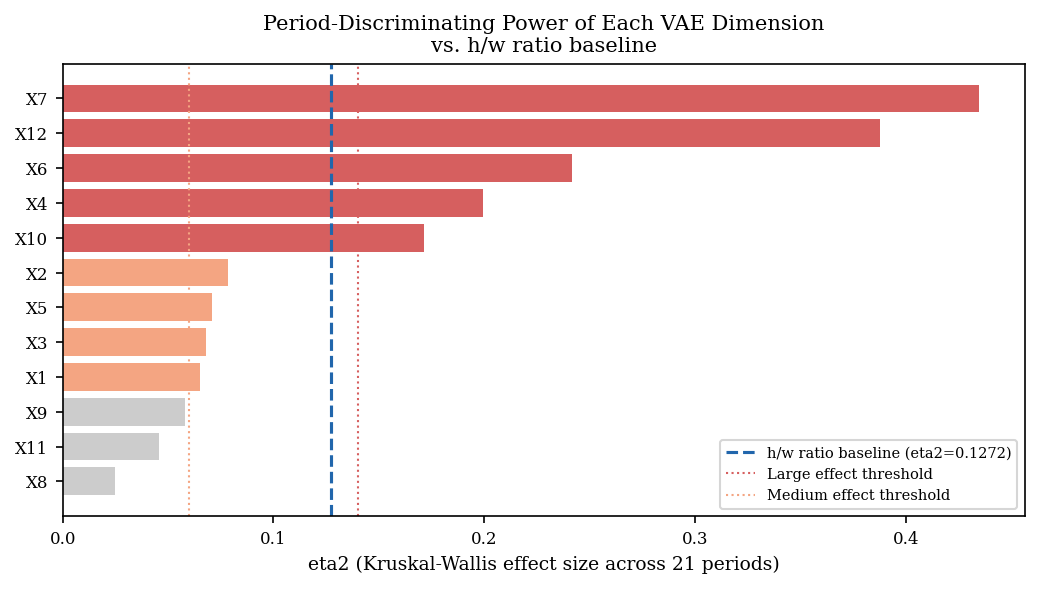

Saved: fig_vae_kw_per_dim.pdf


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
kw_plot = kw_df.sort_values('eta2')
bar_col = ['#D65F5F' if e>=0.14 else ('#F4A582' if e>=0.06 else '#CCCCCC')
           for e in kw_plot['eta2']]
ax.barh(kw_plot['Dimension'], kw_plot['eta2'], color=bar_col)
# Baseline: h/w ratio
ax.axvline(0.1272, color='#2166AC', ls='--', lw=1.5,
           label='h/w ratio baseline (eta2=0.1272)')
ax.axvline(0.14, color='#D65F5F', ls=':', lw=1, label='Large effect threshold')
ax.axvline(0.06, color='#F4A582', ls=':', lw=1, label='Medium effect threshold')
ax.set_xlabel('eta2 (Kruskal-Wallis effect size across 21 periods)')
ax.set_title('Period-Discriminating Power of Each VAE Dimension\nvs. h/w ratio baseline')
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_kw_per_dim.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_vae_kw_per_dim.pdf')

## 3. Which dimensions show a diachronic trend?

Spearman rank correlation between chronological order and per-period
median value, computed independently for each VAE dimension.

This answers: **does this shape feature change directionally over time?**
A significant rho means the feature captures historical change, not just
period distinctiveness. A dimension may have high KW eta2 (periods differ)
but low |rho| (no directional trend) — meaning it captures period-specific
signals that are not part of the long-term drift.

Comparison baseline: h/w ratio Spearman rho = -0.7327 (notebook 2.2).

In [5]:
spear_results = []
for dim in VAE_DIMS:
    meds = (vae_clean.groupby('Period_Name')[dim].median()
            .reindex(PERIOD_CHRON_ORDER).dropna())
    rho, p_s = spearmanr(np.arange(1, len(meds)+1), meds.values)
    spear_results.append({
        'Dimension': dim,
        'rho': round(rho, 4),
        'p': round(p_s, 6),
        'sig': '***' if p_s<0.001 else ('**' if p_s<0.01 else ('*' if p_s<0.05 else 'ns'))
    })

spear_df = pd.DataFrame(spear_results).sort_values('rho')
print('Spearman rho per VAE dimension (chronological trend):')
print(f'Baseline for comparison: h/w ratio rho = -0.7327 (from notebook 2.2)')
print()
print(spear_df.to_string(index=False))

Spearman rho per VAE dimension (chronological trend):
Baseline for comparison: h/w ratio rho = -0.7327 (from notebook 2.2)

Dimension     rho        p sig
       X8 -0.5727 0.006657  **
       X7 -0.4299 0.051782  ns
      X10 -0.3623 0.106491  ns
       X1 -0.2545 0.265488  ns
       X4 -0.1026 0.658097  ns
      X11 -0.0312 0.893308  ns
       X6  0.0455 0.844888  ns
       X3  0.1597 0.489151  ns
       X5  0.1727 0.454024  ns
      X12  0.2104 0.359984  ns
       X9  0.2935 0.196593  ns
       X2  0.6545 0.001284  **


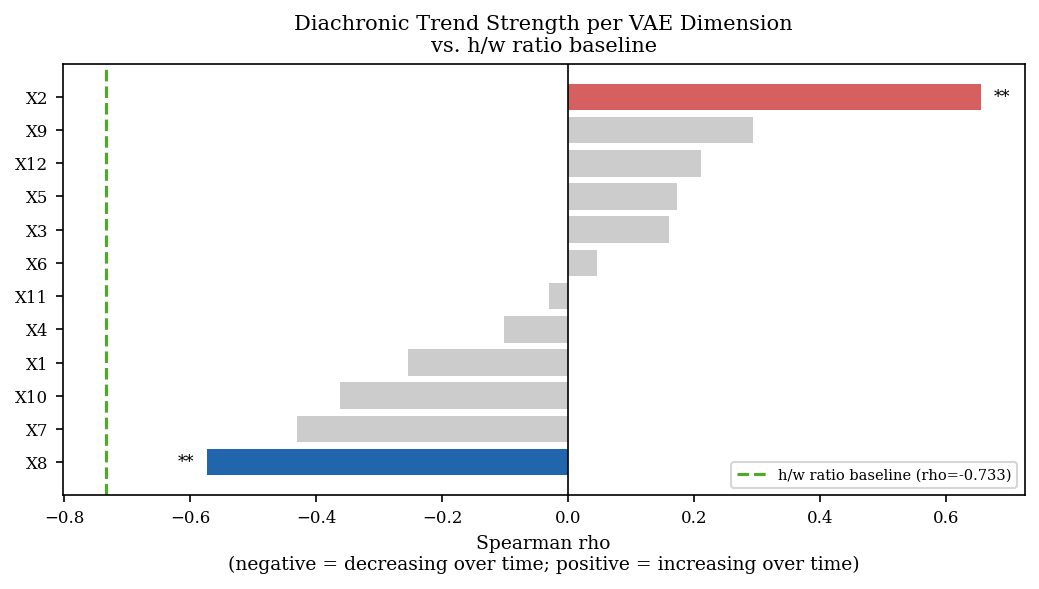

Saved: fig_vae_spearman_per_dim.pdf


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sp_plot = spear_df.sort_values('rho')
bar_col = ['#2166AC' if (r < -0.3 and s!='ns') else
           ('#D65F5F' if (r > 0.3 and s!='ns') else '#CCCCCC')
           for r, s in zip(sp_plot['rho'], sp_plot['sig'])]
ax.barh(sp_plot['Dimension'], sp_plot['rho'], color=bar_col)
ax.axvline(0, color='black', lw=0.8)
# Baseline: h/w ratio
ax.axvline(-0.7327, color='#4DAC26', ls='--', lw=1.5,
           label='h/w ratio baseline (rho=-0.733)')
# Significance stars
for i, (_, row) in enumerate(sp_plot.iterrows()):
    if row['sig'] != 'ns':
        xpos = row['rho'] + (0.02 if row['rho'] >= 0 else -0.02)
        ha = 'left' if row['rho'] >= 0 else 'right'
        ax.text(xpos, i, row['sig'], va='center', ha=ha, fontsize=8)
ax.set_xlabel('Spearman rho\n(negative = decreasing over time; positive = increasing over time)')
ax.set_title('Diachronic Trend Strength per VAE Dimension\nvs. h/w ratio baseline')
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_spearman_per_dim.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_vae_spearman_per_dim.pdf')

## 4. Joint view: discriminating power vs. diachronic trend

A scatter plot of eta2 (period discrimination) vs. |rho| (trend strength)
for each dimension, with the h/w ratio plotted as a reference point.

**Quadrant interpretation:**
- High eta2, high |rho|: dimension discriminates periods AND trends over time
  — captures the same signal as h/w ratio (or a complementary long-term shift)
- High eta2, low |rho|: dimension discriminates periods but does NOT trend
  — captures period-specific shape signatures beyond the long-term drift
- Low eta2, high |rho|: dimension trends weakly but consistently
- Low eta2, low |rho|: dimension carries little historical signal

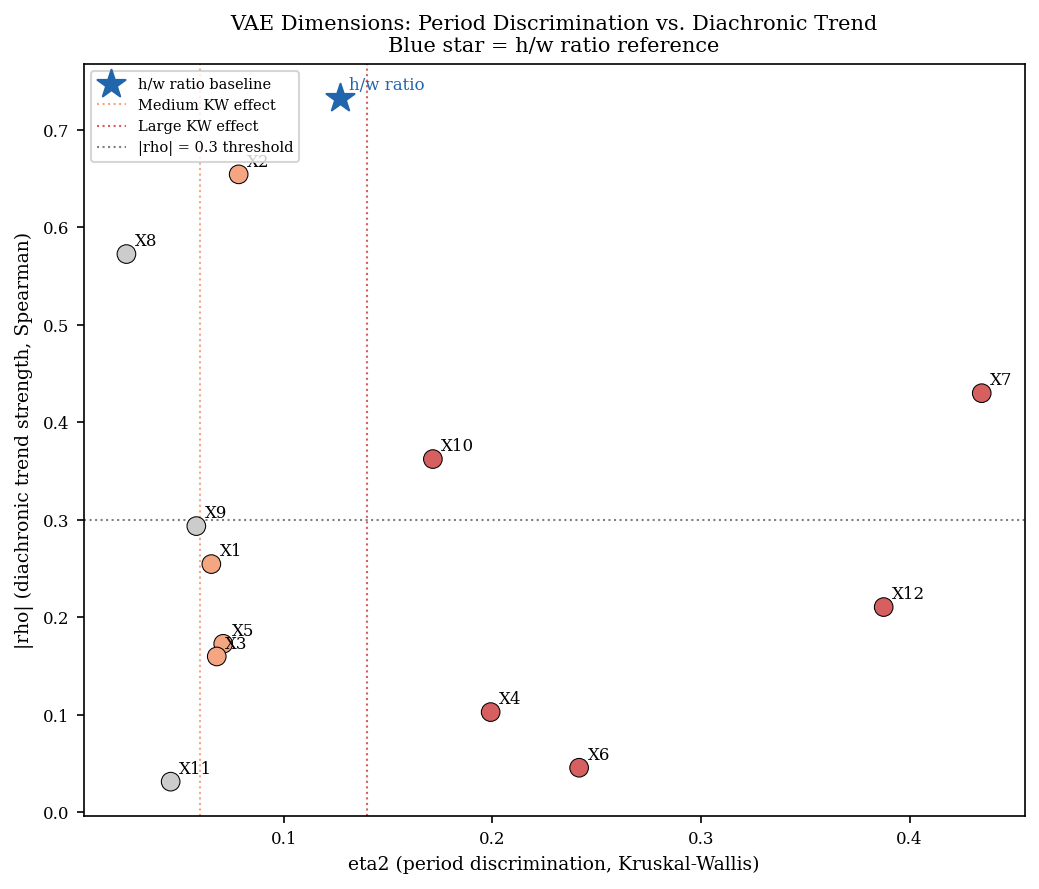

Saved: fig_vae_discrimination_vs_trend.pdf


In [7]:
merged = (kw_df.set_index('Dimension')[['eta2','effect']]
          .join(spear_df.set_index('Dimension')[['rho','p','sig']]))
merged['abs_rho'] = merged['rho'].abs()

fig, ax = plt.subplots(figsize=(7, 6))
scatter_col = ['#D65F5F' if e>=0.14 else ('#F4A582' if e>=0.06 else '#CCCCCC')
               for e in merged['eta2']]
ax.scatter(merged['eta2'], merged['abs_rho'], c=scatter_col, s=80, zorder=3,
           edgecolors='black', lw=0.5)
for dim, row in merged.iterrows():
    ax.annotate(dim, (row['eta2'], row['abs_rho']),
                fontsize=8, xytext=(4, 4), textcoords='offset points')

# Baseline: h/w ratio
ax.scatter([0.1272], [0.7327], marker='*', s=200, color='#2166AC', zorder=4,
           label='h/w ratio baseline')
ax.annotate('h/w ratio', (0.1272, 0.7327), fontsize=8, color='#2166AC',
            xytext=(4, 4), textcoords='offset points')

ax.axvline(0.06, color='#F4A582', ls=':', lw=1, label='Medium KW effect')
ax.axvline(0.14, color='#D65F5F', ls=':', lw=1, label='Large KW effect')
ax.axhline(0.3, color='gray', ls=':', lw=1, label='|rho| = 0.3 threshold')

ax.set_xlabel('eta2 (period discrimination, Kruskal-Wallis)')
ax.set_ylabel('|rho| (diachronic trend strength, Spearman)')
ax.set_title('VAE Dimensions: Period Discrimination vs. Diachronic Trend\nBlue star = h/w ratio reference')
ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_discrimination_vs_trend.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_vae_discrimination_vs_trend.pdf')

## 5. Diachronic trajectories for top VAE dimensions

For each of the top 3 most-trending dimensions (by |rho|), plot the
per-period median with 95% bootstrap confidence intervals.

**Interpretation note:** What each dimension actually *controls* in shape
space can only be determined by traversing the latent space and observing
the decoded silhouettes (notebook 12). After running this cell, check
the traversal outputs for the top dimensions identified here.

In [8]:
# Identify top 3 trending dimensions by |rho|
top_trend_dims = (spear_df.assign(abs_rho=spear_df['rho'].abs())
                  .sort_values('abs_rho', ascending=False)
                  .head(3)['Dimension'].tolist())
print(f'Top 3 diachronically trending dimensions: {top_trend_dims}')
print('Run notebook 12 with these dimension indices to see what shape feature each controls.')

Top 3 diachronically trending dimensions: ['X2', 'X8', 'X7']
Run notebook 12 with these dimension indices to see what shape feature each controls.


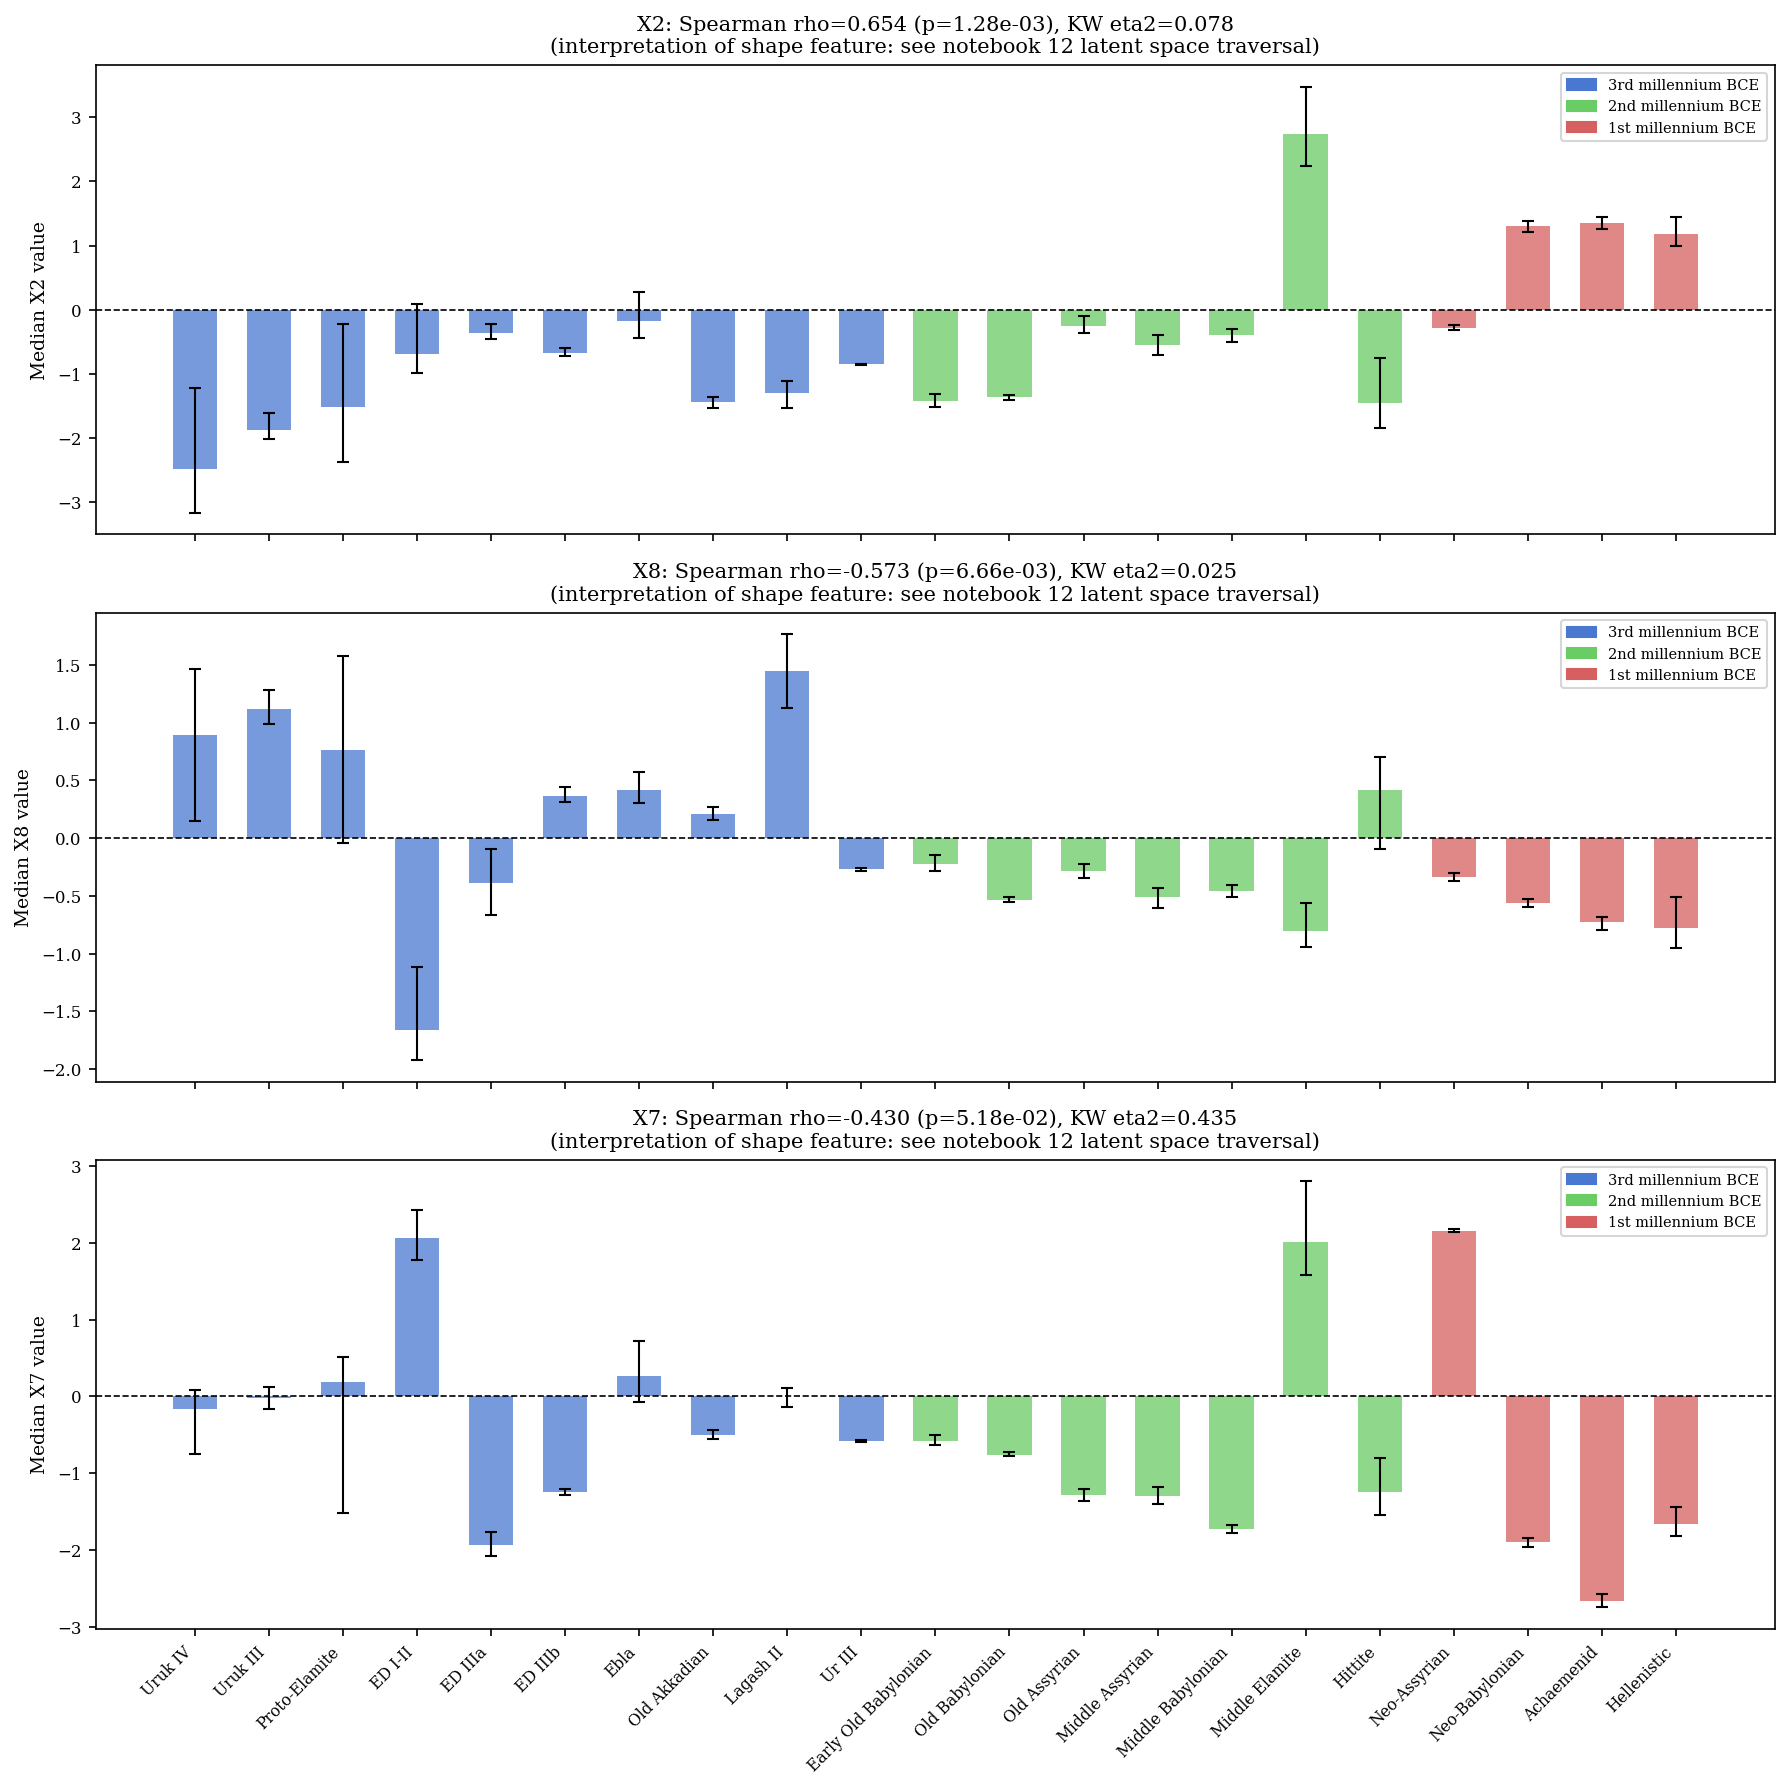

Saved: fig_vae_top_dim_trajectories.pdf


In [9]:
np.random.seed(42)
N_BOOT = 3000
p2m = vae_clean.drop_duplicates('Period_Name').set_index('Period_Name')['millennium'].to_dict()

fig, axes = plt.subplots(len(top_trend_dims), 1, figsize=(12, 4*len(top_trend_dims)),
                         sharex=True)
if len(top_trend_dims) == 1:
    axes = [axes]

for ax, dim in zip(axes, top_trend_dims):
    meds = (vae_clean.groupby('Period_Name')[dim].median()
            .reindex(PERIOD_CHRON_ORDER).dropna())
    rho_d = spear_df.set_index('Dimension').loc[dim, 'rho']
    p_d   = spear_df.set_index('Dimension').loc[dim, 'p']
    eta2_d = kw_df.set_index('Dimension').loc[dim, 'eta2']

    ci_lo, ci_hi = [], []
    for p in meds.index:
        vals = vae_clean.loc[vae_clean['Period_Name']==p, dim].values
        boot = [np.median(np.random.choice(vals, len(vals), replace=True)) for _ in range(N_BOOT)]
        ci_lo.append(np.percentile(boot, 2.5))
        ci_hi.append(np.percentile(boot, 97.5))

    x = np.arange(len(meds))
    colors = [PALETTE.get(p2m.get(p,''), '#888') for p in meds.index]
    ax.bar(x, meds.values, color=colors, alpha=0.75, width=0.6, zorder=2)
    ax.errorbar(x, meds.values,
                yerr=[meds.values-np.array(ci_lo), np.array(ci_hi)-meds.values],
                fmt='none', color='black', capsize=3, lw=1, zorder=3)
    ax.axhline(0, color='black', ls='--', lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(meds.index, rotation=45, ha='right', fontsize=7.5)
    ax.set_ylabel(f'Median {dim} value')
    ax.set_title(
        f'{dim}: Spearman rho={rho_d:.3f} (p={p_d:.2e}), KW eta2={eta2_d:.3f}\n'
        '(interpretation of shape feature: see notebook 12 latent space traversal)'
    )
    handles = [mpatches.Patch(color=v, label=k) for k,v in PALETTE.items()]
    ax.legend(handles=handles, fontsize=7, loc='upper right')

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_top_dim_trajectories.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_vae_top_dim_trajectories.pdf')

Genre counts per period (top 3 genres):

  Administrative:
Period_Name
Uruk IV                    13
Uruk III                  311
Proto-Elamite              16
ED I-II                    68
ED IIIa                   136
ED IIIb                  1214
Ebla                      456
Old Akkadian             2488
Lagash II                 120
Ur III                  26574
Early Old Babylonian      353
Old Babylonian           4540
Old Assyrian               78
Middle Assyrian           281
Middle Babylonian        3910
Middle Elamite             19
Hittite                     0
Neo-Assyrian              455
Neo-Babylonian           1432
Achaemenid                474
Hellenistic                 3

  Literary:
Period_Name
Uruk IV                    0
Uruk III                   0
Proto-Elamite              0
ED I-II                    0
ED IIIa                    1
ED IIIb                    1
Ebla                       1
Old Akkadian               3
Lagash II                  0
Ur III       

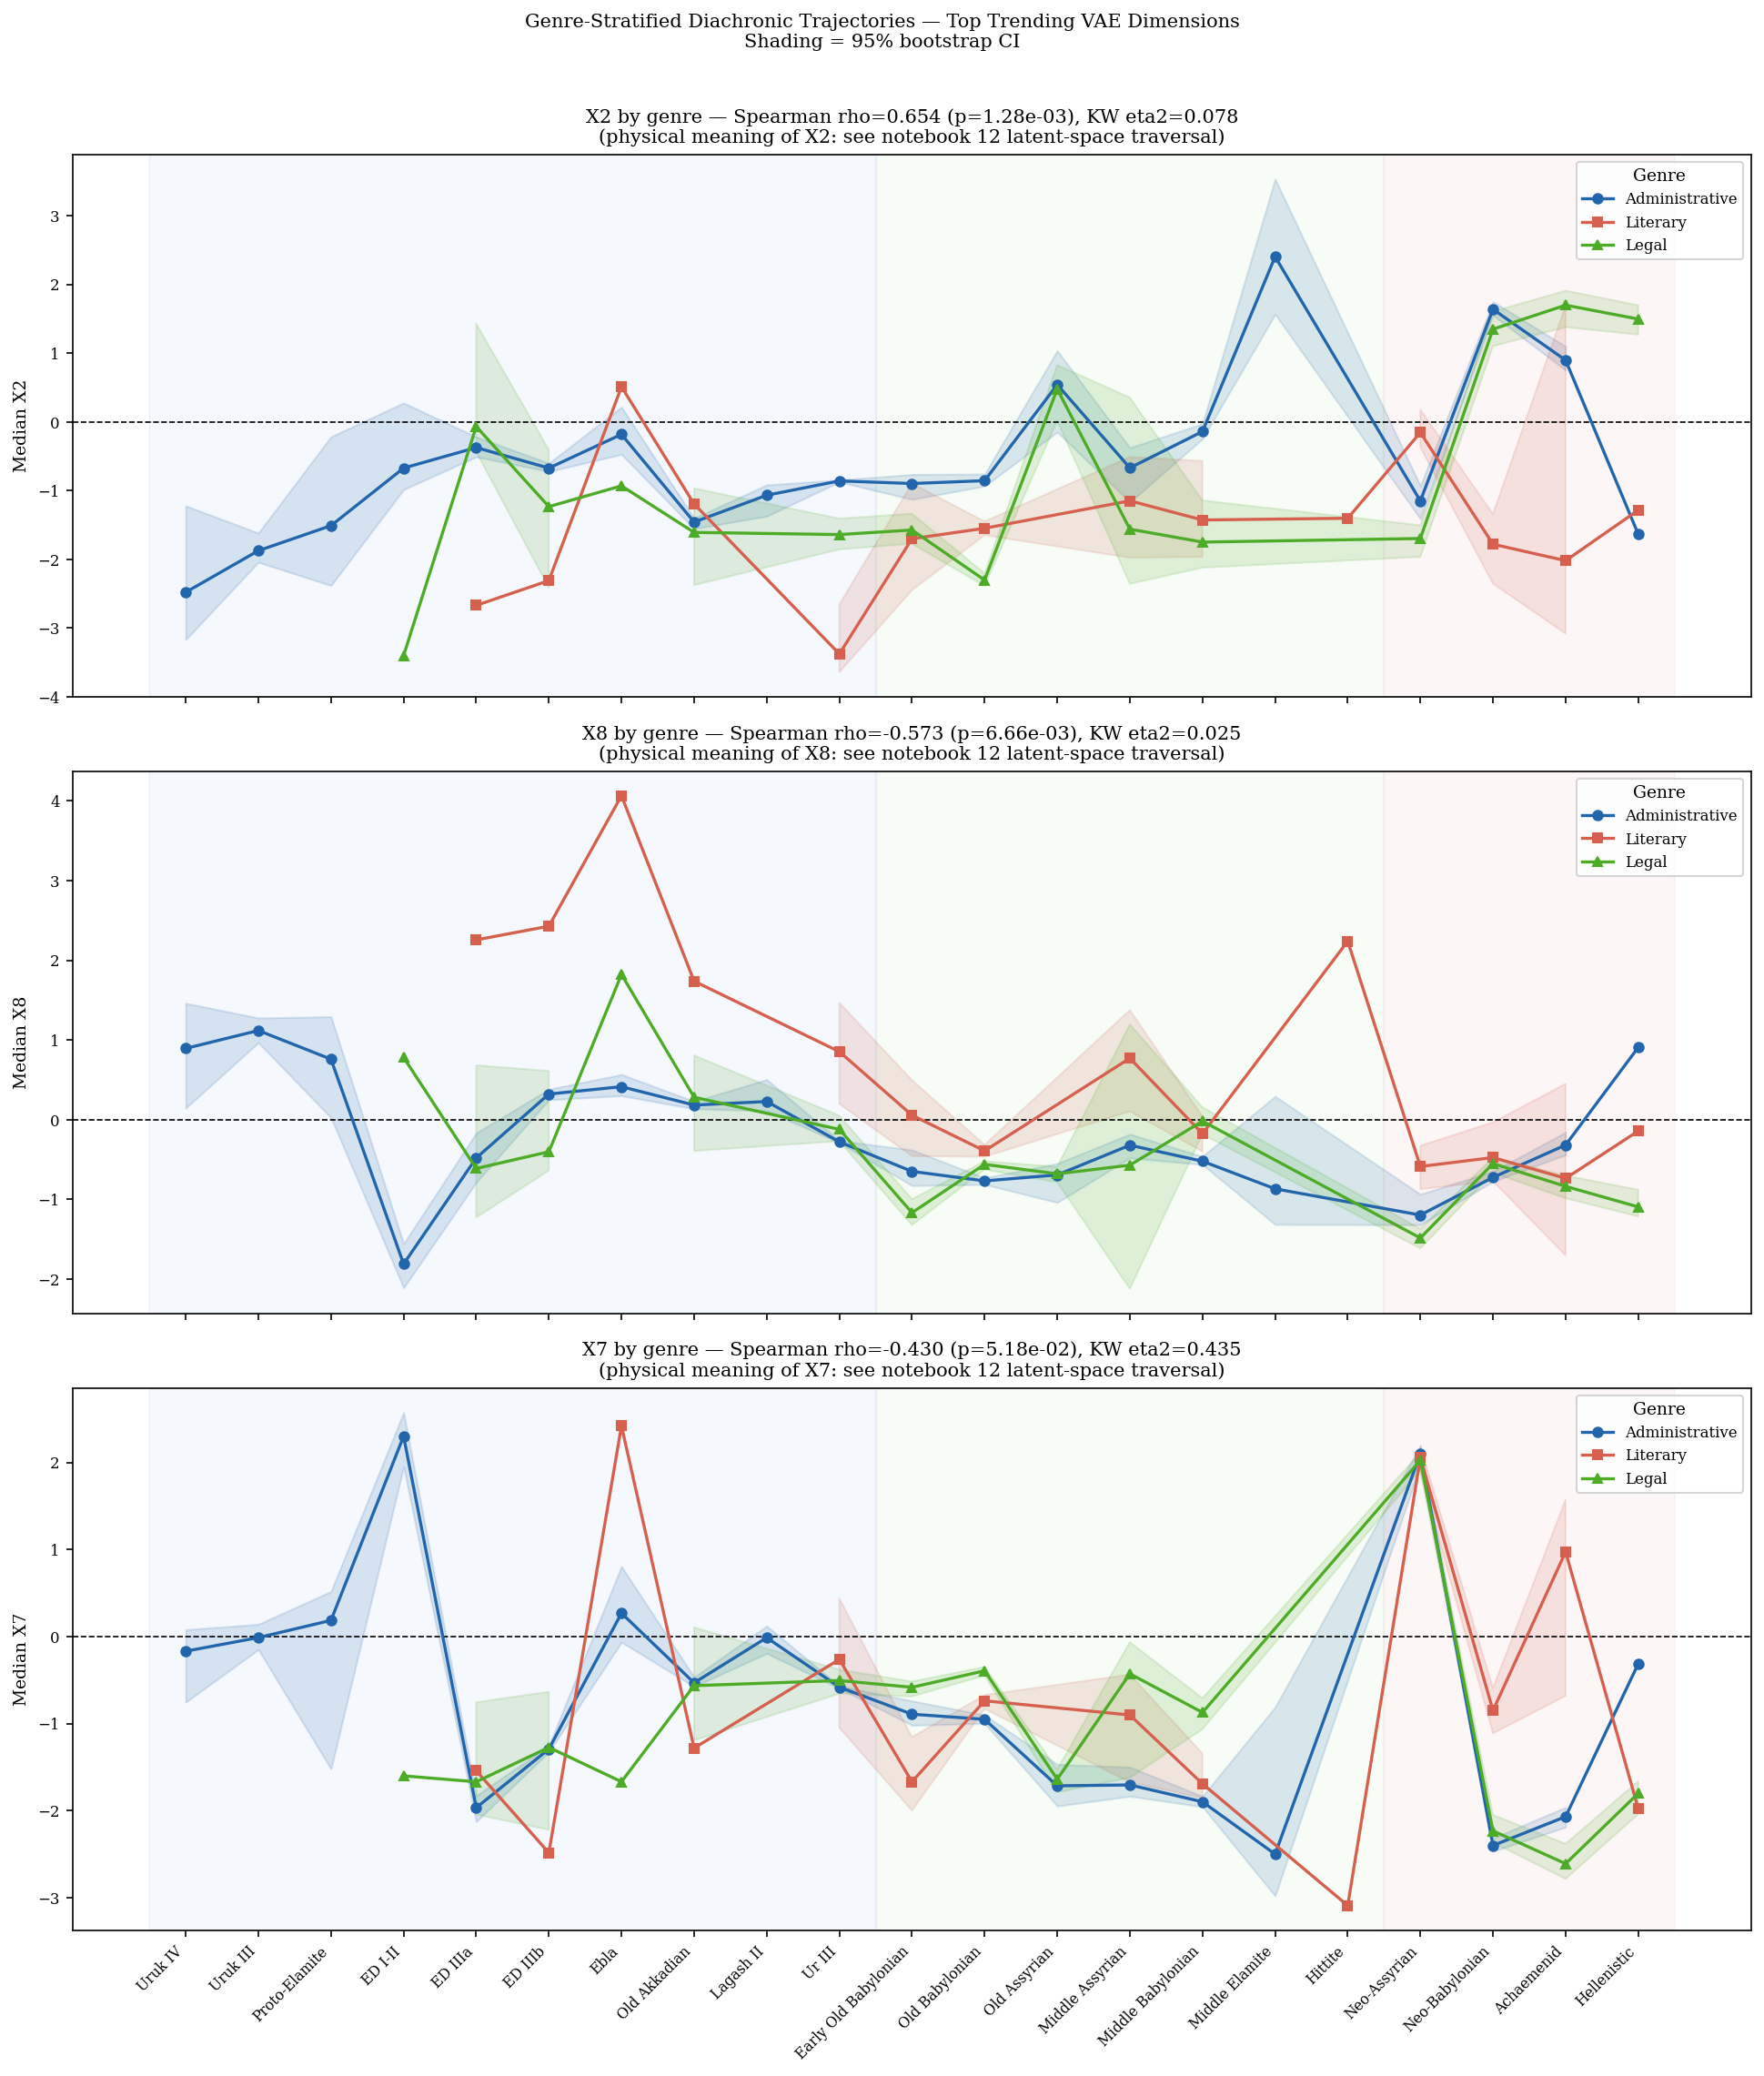

Saved: fig_vae_genre_trajectories.pdf


In [10]:
np.random.seed(42)
N_BOOT = 2000
GENRES_TO_PLOT = ['Administrative', 'Literary', 'Legal']
GENRE_COLORS   = {'Administrative': '#2166AC', 'Literary': '#D6604D', 'Legal': '#4DAC26'}
GENRE_MARKERS  = {'Administrative': 'o', 'Literary': 's', 'Legal': '^'}

# Report genre counts per period for the three genres
print('Genre counts per period (top 3 genres):')
for g in GENRES_TO_PLOT:
    counts = (vae_clean[vae_clean['Genre_Name']==g]
              .groupby('Period_Name').size()
              .reindex(PERIOD_CHRON_ORDER).fillna(0).astype(int))
    print(f'\n  {g}:')
    print(counts.to_string())

fig, axes = plt.subplots(len(top_trend_dims), 1,
                         figsize=(13, 5 * len(top_trend_dims)), sharex=True)
if len(top_trend_dims) == 1:
    axes = [axes]

for ax, dim in zip(axes, top_trend_dims):
    rho_d  = spear_df.set_index('Dimension').loc[dim, 'rho']
    p_d    = spear_df.set_index('Dimension').loc[dim, 'p']
    eta2_d = kw_df.set_index('Dimension').loc[dim, 'eta2']

    for genre in GENRES_TO_PLOT:
        sub = vae_clean[vae_clean['Genre_Name'] == genre]
        meds = (sub.groupby('Period_Name')[dim].median()
                .reindex(PERIOD_CHRON_ORDER).dropna())
        if len(meds) < 3:
            continue

        ci_lo, ci_hi = [], []
        for p in meds.index:
            vals = sub.loc[sub['Period_Name'] == p, dim].values
            if len(vals) < 5:
                ci_lo.append(np.nan); ci_hi.append(np.nan)
                continue
            boot = [np.median(np.random.choice(vals, len(vals), replace=True))
                    for _ in range(N_BOOT)]
            ci_lo.append(np.percentile(boot, 2.5))
            ci_hi.append(np.percentile(boot, 97.5))

        x_idx = [PERIOD_CHRON_ORDER.index(p) for p in meds.index]
        col = GENRE_COLORS[genre]
        ax.plot(x_idx, meds.values, GENRE_MARKERS[genre] + '-',
                color=col, lw=1.6, ms=5, label=genre, zorder=3)
        ci_lo_a = np.array(ci_lo); ci_hi_a = np.array(ci_hi)
        ax.fill_between(x_idx, ci_lo_a, ci_hi_a, color=col, alpha=0.15)

    # Shade millennia
    mil_bounds = []
    cur = to_millennium(PERIOD_CHRON_ORDER[0]); start = 0
    for i, p in enumerate(PERIOD_CHRON_ORDER):
        m = to_millennium(p)
        if m != cur:
            mil_bounds.append((start, i, cur)); cur, start = m, i
    mil_bounds.append((start, len(PERIOD_CHRON_ORDER), cur))
    for s, e, m in mil_bounds:
        ax.axvspan(s - 0.5, e - 0.5, alpha=0.05, color=PALETTE[m])

    ax.axhline(0, color='black', ls='--', lw=0.8)
    ax.set_xticks(range(len(PERIOD_CHRON_ORDER)))
    ax.set_xticklabels(PERIOD_CHRON_ORDER, rotation=45, ha='right', fontsize=7.5)
    ax.set_ylabel(f'Median {dim}')
    ax.set_title(
        f'{dim} by genre — Spearman rho={rho_d:.3f} (p={p_d:.2e}), KW eta2={eta2_d:.3f}\n'
        f'(physical meaning of {dim}: see notebook 12 latent-space traversal)'
    )
    ax.legend(title='Genre', fontsize=8, loc='upper right')

plt.suptitle('Genre-Stratified Diachronic Trajectories — Top Trending VAE Dimensions\n'
             'Shading = 95% bootstrap CI', y=1.01, fontsize=10)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_genre_trajectories.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_vae_genre_trajectories.pdf')

## 5b. Genre-stratified trajectories for top trending dimensions

Do the top trending dimensions change uniformly across all scribal traditions,
or is the diachronic signal concentrated in one genre?

We compare Administrative, Literary, and Legal genres — the three largest
genre groups — on the same axis for each of the top trending dimensions.

A dimension that trends in **all three genres** reflects a universal shift in
tablet production practice. A dimension that trends only in **Administrative**
texts suggests scribal bureaucracy drove the shape change. A dimension trending
only in **Literary** texts would implicate the first-millennium scholarly
tradition (omen series, astronomical diaries) as the source.

## 6. Standardization (CV) per dimension — administrative genre

For each VAE dimension, compute the coefficient of variation (CV) within
each period for administrative tablets only.

Low CV = the shape feature is uniform within that period (high institutional
control over that particular shape aspect). High CV = diverse practice.

This extends the standardization analysis from ratio-based CV (notebooks 2.2/2.3)
to each individual shape feature the VAE has learned.

In [11]:
vae_admin = vae_clean[vae_clean['Genre_Name']=='Administrative'].copy()
print(f'Administrative tablets: {len(vae_admin):,}')

cv_rows = []
for p in PERIOD_CHRON_ORDER:
    sub = vae_admin.loc[vae_admin['Period_Name']==p, VAE_DIMS]
    if len(sub) < 10:
        continue
    row = {'Period': p, 'n': len(sub)}
    for dim in VAE_DIMS:
        vals = sub[dim].values
        mean_abs = abs(np.mean(vals))
        row[dim] = round(np.std(vals, ddof=1) / mean_abs, 3) if mean_abs > 0.1 else np.nan
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows).set_index('Period')
print('CV per VAE dimension per period (administrative genre):')
print(cv_df.to_string())

Administrative tablets: 42,941
CV per VAE dimension per period (administrative genre):
                          n     X1      X2     X3      X4      X5     X6     X7      X8      X9     X10    X11    X12
Period                                                                                                               
Uruk IV                  13  1.974   2.291    NaN   2.605   1.478  3.055  4.347   2.070   1.688   4.672  2.220  2.567
Uruk III                311  2.944   1.216  4.821  11.442   8.353  1.795  7.822   2.322   1.706   2.593  3.231  0.714
Proto-Elamite            16    NaN   1.311  3.645  10.803   4.928  3.403  2.981   1.569   0.984   4.225  4.924  0.439
ED I-II                  68  2.011  19.204  2.156   4.067   2.045  0.980  0.401   0.841   6.331   3.292  0.856  4.633
ED IIIa                 136  6.893   4.563  4.874   2.000   1.321  1.787  0.597   5.114  12.115   2.337  3.757  0.556
ED IIIb                1214  1.659   2.010  5.291   1.936   1.269  1.418  0.756   3.087

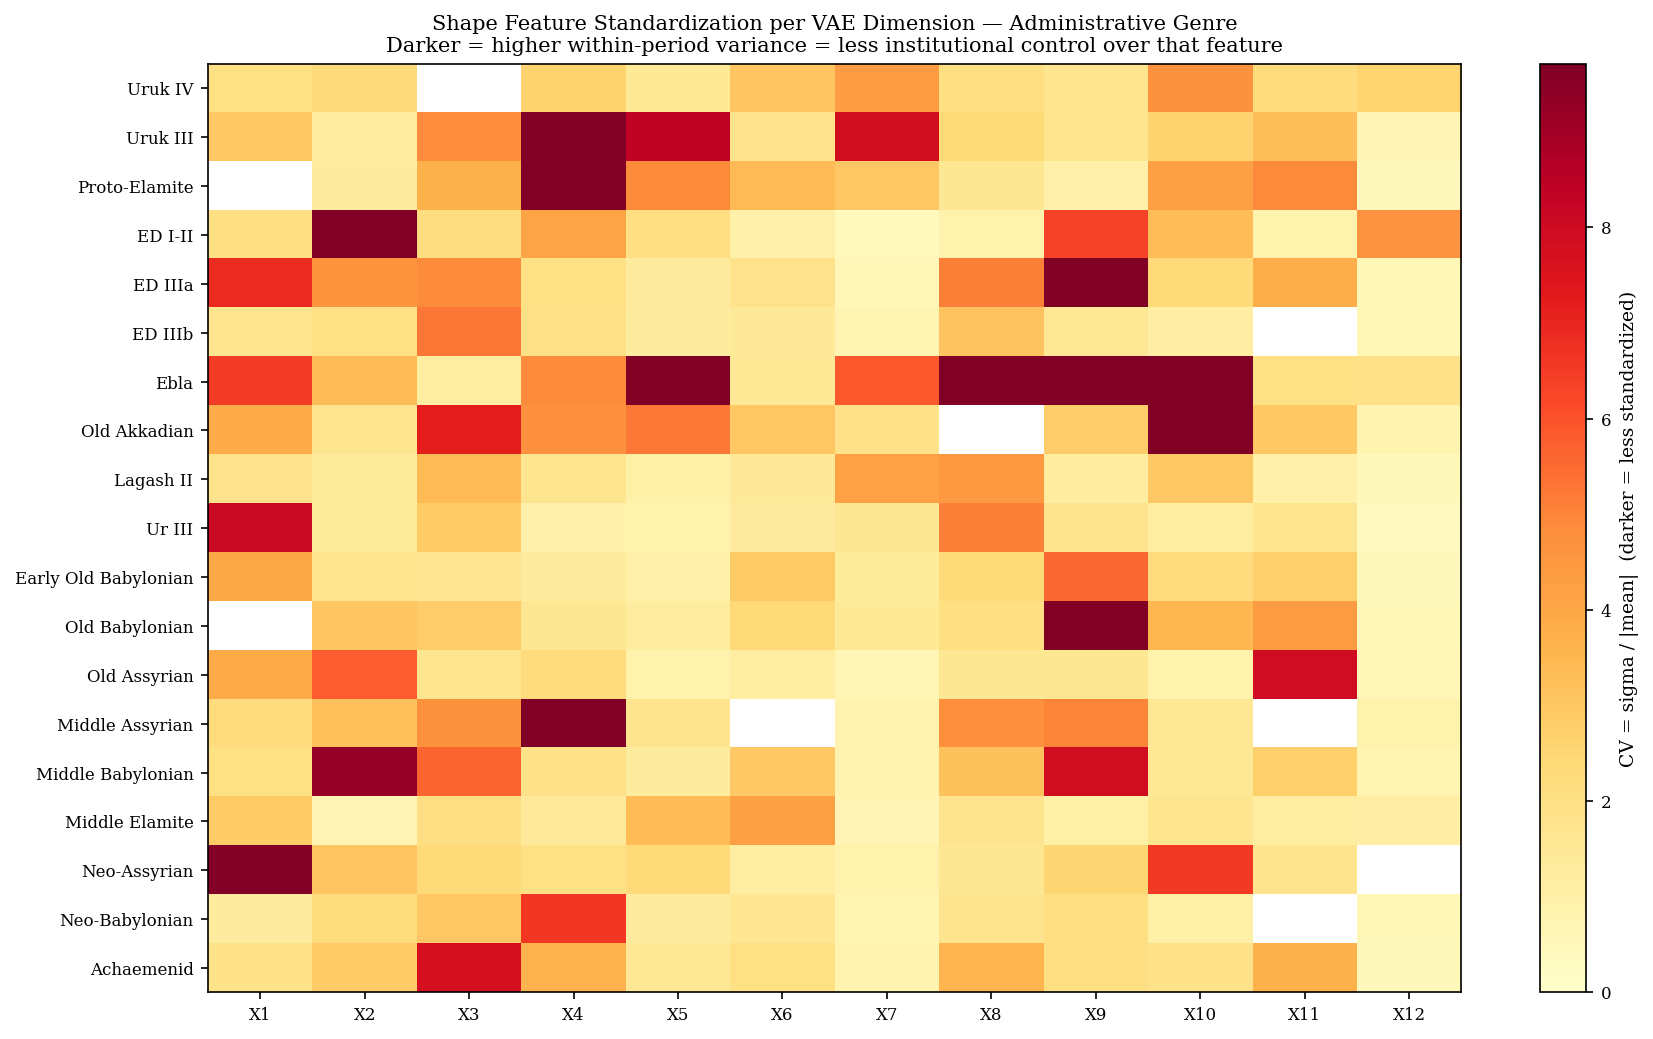

Saved: fig_vae_cv_heatmap.pdf


In [12]:
cv_plot = cv_df[VAE_DIMS].copy()
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(cv_plot.values, aspect='auto', cmap='YlOrRd',
               vmin=0, vmax=np.nanpercentile(cv_plot.values, 95))
ax.set_xticks(range(12))
ax.set_xticklabels(VAE_DIMS)
ax.set_yticks(range(len(cv_plot)))
ax.set_yticklabels(cv_plot.index, fontsize=8)
plt.colorbar(im, ax=ax, label='CV = sigma / |mean|  (darker = less standardized)')
ax.set_title(
    'Shape Feature Standardization per VAE Dimension — Administrative Genre\n'
    'Darker = higher within-period variance = less institutional control over that feature'
)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_cv_heatmap.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_vae_cv_heatmap.pdf')

## 7. Period mean VAE vectors — shape fingerprints

Heatmap of mean VAE vector per period (all tablets, all genres).
Each row is a period's average 'shape fingerprint' in the 12-dimensional space.
Visible structure (columns with strong variation across rows) indicates
dimensions that the model has found useful to distinguish periods.

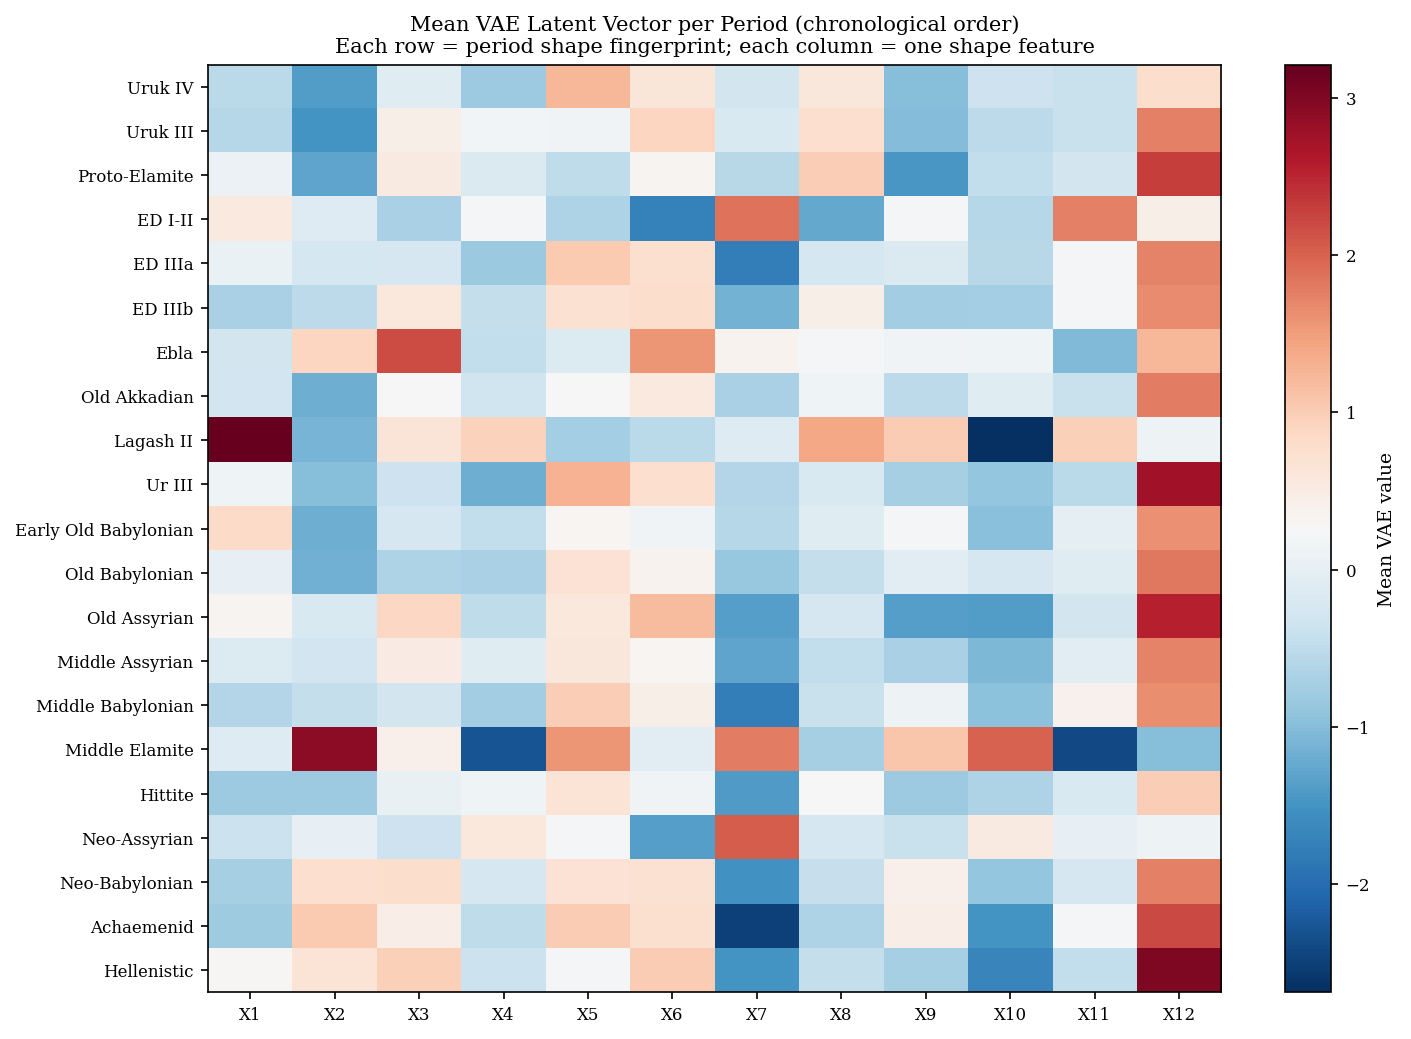

Saved: fig_vae_mean_heatmap.pdf
Saved: vae_period_mean_vectors.csv


In [13]:
periods_present = [p for p in PERIOD_CHRON_ORDER
                   if vae_clean['Period_Name'].eq(p).sum() >= 10]
mean_matrix = np.array([
    vae_clean.loc[vae_clean['Period_Name']==p, VAE_DIMS].mean().values
    for p in periods_present
])

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(mean_matrix, aspect='auto', cmap='RdBu_r')
ax.set_xticks(range(12))
ax.set_xticklabels(VAE_DIMS)
ax.set_yticks(range(len(periods_present)))
ax.set_yticklabels(periods_present, fontsize=8)
plt.colorbar(im, ax=ax, label='Mean VAE value')
ax.set_title(
    'Mean VAE Latent Vector per Period (chronological order)\n'
    'Each row = period shape fingerprint; each column = one shape feature'
)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_mean_heatmap.pdf', bbox_inches='tight')
# Save for comparison notebook
mean_vec_df = pd.DataFrame(mean_matrix, index=periods_present, columns=VAE_DIMS)
mean_vec_df.index.name = 'Period'
mean_vec_df.reset_index().to_csv(f'{FIGURES_DIR}/vae_period_mean_vectors.csv', index=False)
plt.show()
print('Saved: fig_vae_mean_heatmap.pdf')
print('Saved: vae_period_mean_vectors.csv')

## 8. Pairwise Euclidean distance between period mean vectors

This is the distance matrix underlying the dendrogram in notebook 11.1.
Most-similar pairs = historically continuous cultures; most-distant = greatest
shape divergence across the corpus.

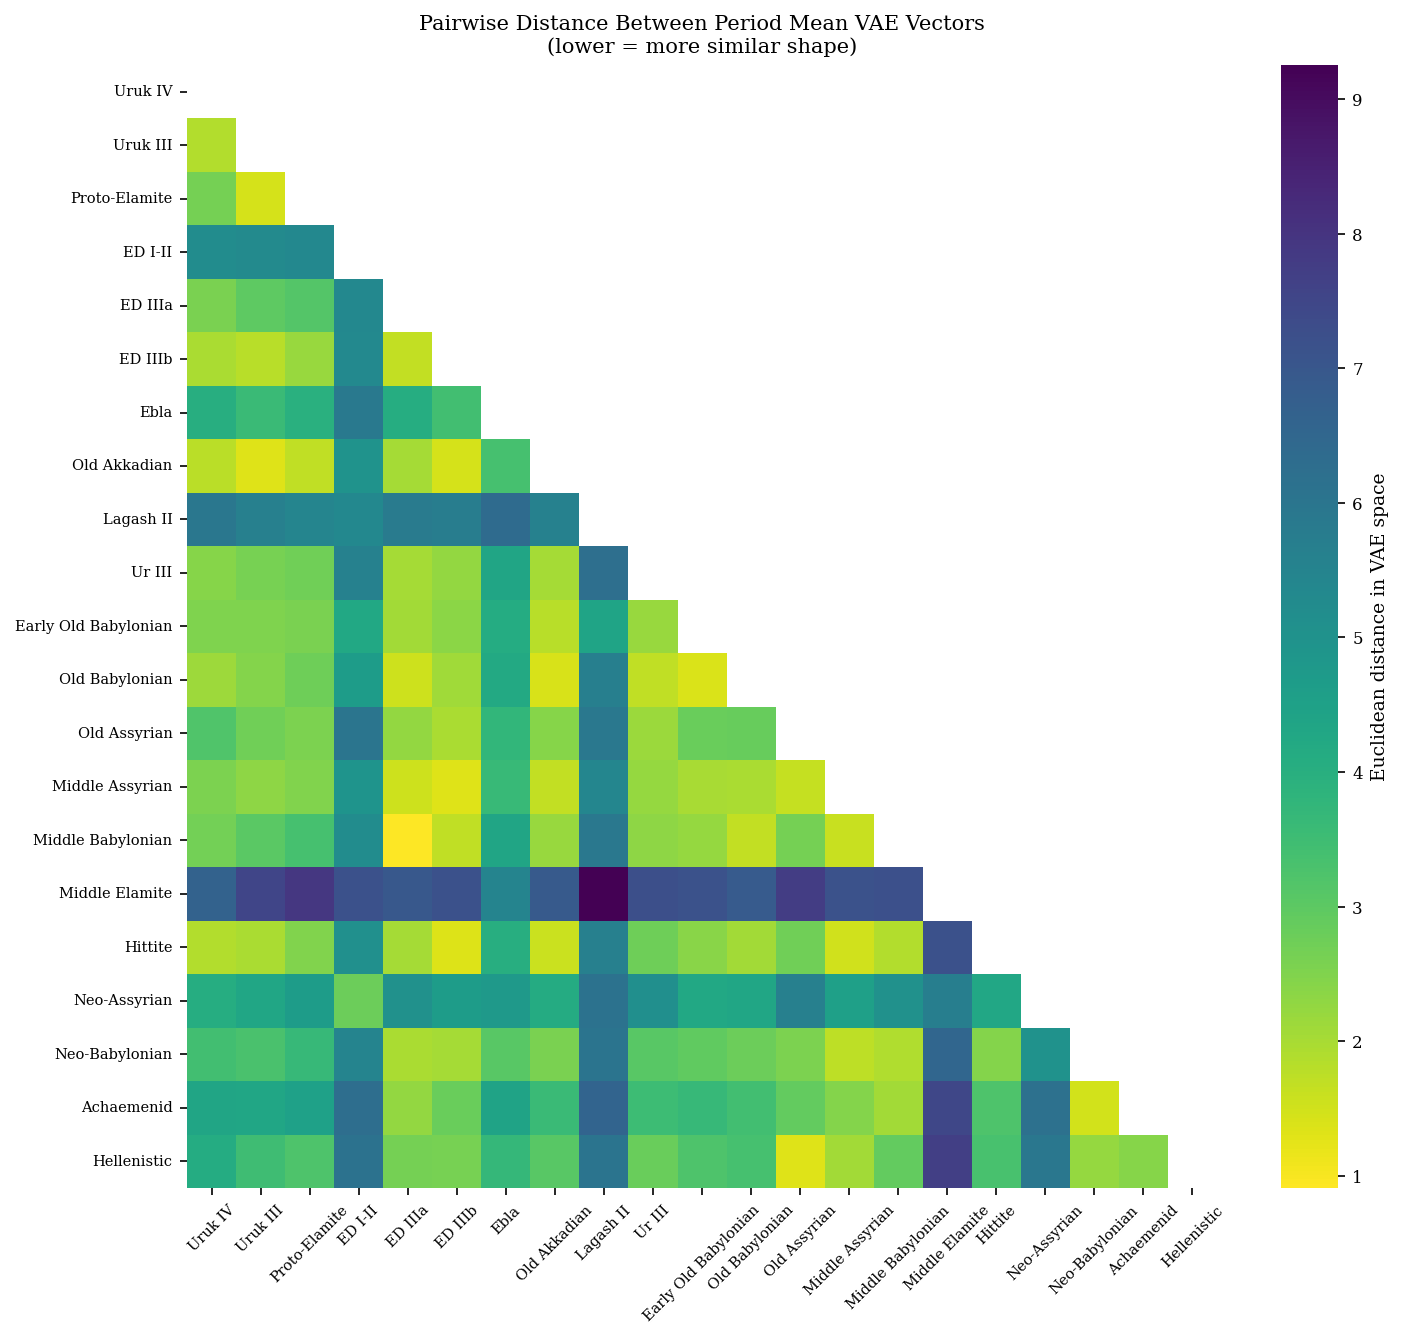

Most similar period pairs (full shape space):
Middle Babylonian  ED IIIa         0.907910
Old Akkadian       Uruk III        1.305452
Hellenistic        Old Assyrian    1.309595
Middle Assyrian    ED IIIb         1.320383
Hittite            ED IIIb         1.362465

Most distant period pairs:
Middle Elamite  Uruk III          7.546275
Hellenistic     Middle Elamite    7.708175
Middle Elamite  Old Assyrian      7.778286
                Proto-Elamite     7.927583
                Lagash II         9.254836

Saved: fig_vae_distance_matrix.pdf


In [14]:
dist_matrix = squareform(pdist(mean_matrix, metric='euclidean'))
dist_df = pd.DataFrame(dist_matrix, index=periods_present, columns=periods_present)

fig, ax = plt.subplots(figsize=(10, 9))
mask = np.triu(np.ones(dist_matrix.shape, dtype=bool))
sns.heatmap(dist_df, mask=mask, cmap='viridis_r', ax=ax,
            xticklabels=True, yticklabels=True,
            cbar_kws={'label': 'Euclidean distance in VAE space'})
ax.set_title('Pairwise Distance Between Period Mean VAE Vectors\n(lower = more similar shape)')
ax.tick_params(axis='x', rotation=45, labelsize=7)
ax.tick_params(axis='y', labelsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_vae_distance_matrix.pdf', bbox_inches='tight')
plt.show()

flat = dist_df.where(np.tril(np.ones(dist_df.shape), k=-1).astype(bool))
stacked = flat.stack().sort_values()
print('Most similar period pairs (full shape space):')
print(stacked.head(5).to_string())
print('\nMost distant period pairs:')
print(stacked.tail(5).to_string())
print('\nSaved: fig_vae_distance_matrix.pdf')

## 9. Summary and next steps

After running this notebook:
1. Note the top dimensions by eta2 and |rho|
2. Go to **notebook 12 (Traverse the VAE latent space)** and traverse
   those specific dimensions to see what shape feature each controls
3. Return here and annotate the figures with the physical interpretation
4. Notebook 2.5 will combine these results with the ratio analyses

In [15]:
print('=== VAE ANALYSIS SUMMARY ===')
print()
print('Period discrimination (Kruskal-Wallis eta2):')
print(f'  h/w ratio baseline: eta2 = 0.1272')
print(kw_df[['Dimension','eta2','effect']].to_string(index=False))
print()
print('Diachronic trend (Spearman |rho|):')
print(f'  h/w ratio baseline: |rho| = 0.7327')
spear_print = spear_df.assign(abs_rho=spear_df['rho'].abs()).sort_values('abs_rho', ascending=False)
print(spear_print[['Dimension','rho','sig','abs_rho']].to_string(index=False))
print()
print(f'Top trending dims for latent space traversal in notebook 12: {top_trend_dims}')
top_disc = kw_df.head(3)['Dimension'].tolist()
print(f'Top discriminating dims for latent space traversal in notebook 12: {top_disc}')

# Save dimension-level statistics for use in notebook 2.5
dim_stats = (kw_df.set_index('Dimension')[['eta2','effect']]
             .join(spear_df.set_index('Dimension')[['rho','p','sig']]))
dim_stats['abs_rho'] = dim_stats['rho'].abs()
dim_stats.to_csv(f'{FIGURES_DIR}/vae_dim_stats.csv')
print(f'\nSaved: vae_dim_stats.csv')

import glob
print('\nFigures saved to paper/figures/:')
for fn in sorted(glob.glob(f'{FIGURES_DIR}/fig_vae*.pdf')):
    print(f'  {os.path.basename(fn)}')

=== VAE ANALYSIS SUMMARY ===

Period discrimination (Kruskal-Wallis eta2):
  h/w ratio baseline: eta2 = 0.1272
Dimension   eta2 effect
       X7 0.4346  large
      X12 0.3876  large
       X6 0.2416  large
       X4 0.1992  large
      X10 0.1715  large
       X2 0.0784 medium
       X5 0.0710 medium
       X3 0.0679 medium
       X1 0.0653 medium
       X9 0.0581  small
      X11 0.0458  small
       X8 0.0246  small

Diachronic trend (Spearman |rho|):
  h/w ratio baseline: |rho| = 0.7327
Dimension     rho sig  abs_rho
       X2  0.6545  **   0.6545
       X8 -0.5727  **   0.5727
       X7 -0.4299  ns   0.4299
      X10 -0.3623  ns   0.3623
       X9  0.2935  ns   0.2935
       X1 -0.2545  ns   0.2545
      X12  0.2104  ns   0.2104
       X5  0.1727  ns   0.1727
       X3  0.1597  ns   0.1597
       X4 -0.1026  ns   0.1026
       X6  0.0455  ns   0.0455
      X11 -0.0312  ns   0.0312

Top trending dims for latent space traversal in notebook 12: ['X2', 'X8', 'X7']
Top discriminating d